# Minimal forest manifold example

This notebook shows the same workflow twice: once for a sparse-proximity Random Forest, and once for a sparse-proximity Rotation Forest. Each model is fit on `datasets/treeData.csv`, turned into a PHATE embedding, and plotted in 2D.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from aeon.classification.sklearn import RotationForestClassifier

# Silence a couple of noisy warnings so the notebook stays beginner-friendly.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Find the repository root and make sure Python can import the local package.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "datasets" / "treeData.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from forestgap import with_sparse_proximity

# These settings control the PHATE visualization.add
phate_kwargs = {
    "n_components": 2,
    "knn": 15,
    "t": "auto",
    "n_landmark": 300,
    "beta": 0.9,
    "verbose": 0,
}

plt.style.use("default")
pd.set_option("display.max_columns", 10)

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\rhodes8\My Drive\repos\ObliqueProximities\ObliqueProximitiesCode.worktrees\copilot-worktree-2026-07-02T17-36-23


In [2]:
# Read the dataset.
data_path = PROJECT_ROOT / "datasets" / "treeData.csv"
tree_data = pd.read_csv(data_path)

# Split the response column from the features.
X = tree_data.drop(columns="branch")
y = tree_data["branch"].astype(int)

print(f"Loaded {data_path.relative_to(PROJECT_ROOT)}")
print(f"X shape: {X.shape}")
print("Branch counts:")
print(y.value_counts().sort_index().to_string())

Loaded datasets\treeData.csv
X shape: (1440, 60)
Branch counts:
branch
1     180
2     140
3     140
4     140
5     140
6     140
7     140
8     140
9     140
10    140


## Random Forest

    SGD-MDS may not have converged: stress changed by -4.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.


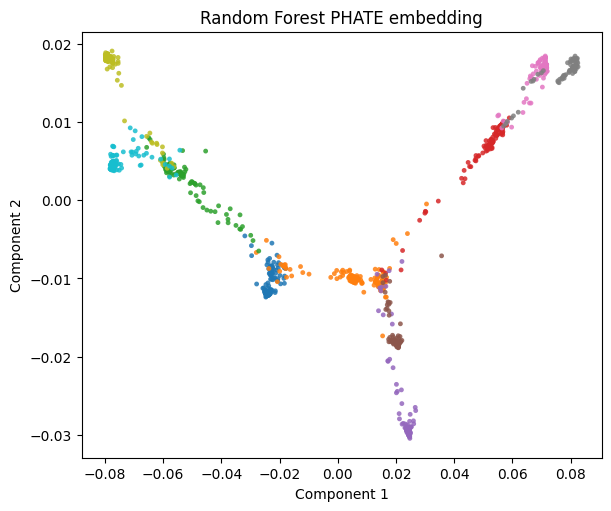

In [3]:
# Create a Random Forest classifier with sparse proximity support.
RandomForestWithProximity = with_sparse_proximity(RandomForestClassifier)
rf_model = RandomForestWithProximity(
    n_estimators=120,
    random_state=42,
    bootstrap=True,
    n_jobs=-1,
    prox_method="rfgap",
    matrix_type="sparse",
    non_zero_diagonal=True,
)

# Fit the model on the training data.
rf_model.fit(X, y)

# Convert the fitted proximities into a 2D PHATE embedding.
rf_embedding = rf_model.phate(**phate_kwargs)

# Plot the embedding.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
cmap = plt.get_cmap("tab10", len(np.unique(y)))
ax.scatter(
    rf_embedding[:, 0],
    rf_embedding[:, 1],
    c=y,
    cmap=cmap,
    s=12,
    alpha=0.85,
    linewidths=0,
)
ax.set_title("Random Forest PHATE embedding")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
plt.show()

## Rotation Forest

    SGD-MDS may not have converged: stress changed by 4.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.


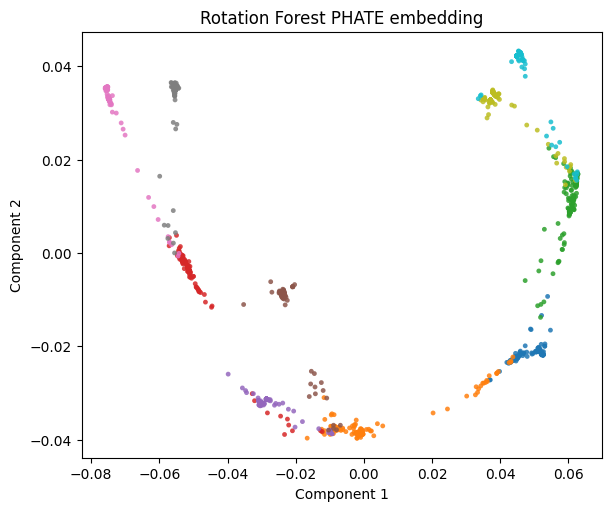

In [4]:
# Create a Rotation Forest classifier with sparse proximity support.
RotationForestWithProximity = with_sparse_proximity(RotationForestClassifier)
rot_model = RotationForestWithProximity(
    n_estimators=80,
    random_state=42,
    n_jobs=-1,
    prox_method="rfgap",
    matrix_type="sparse",
    non_zero_diagonal=True,
)

# Fit the model on the same dataset.
rot_model.fit(X, y)

# Convert the fitted proximities into a 2D PHATE embedding.
rot_embedding = rot_model.phate(**phate_kwargs)

# Plot the embedding.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
cmap = plt.get_cmap("tab10", len(np.unique(y)))
ax.scatter(
    rot_embedding[:, 0],
    rot_embedding[:, 1],
    c=y,
    cmap=cmap,
    s=12,
    alpha=0.85,
    linewidths=0,
)
ax.set_title("Rotation Forest PHATE embedding")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
plt.show()